In [7]:
import argparse
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN
import torch
import torch.nn as nn

In [26]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim=2, latent_dim=32):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder_lstm = nn.LSTM(input_dim, latent_dim, batch_first=True)
        # The decoder keeps a 32-size memory and a Linear layer maps each step back to an (x, y) pair
        self.decoder_lstm = nn.LSTM(latent_dim, latent_dim, batch_first=True)
        self.output_layer = nn.Linear(latent_dim, input_dim)

    def encode(self, packed_sequences):
        """Passes raw packed data down into the uniform Latent Space vector."""
        _, (hidden, _) = self.encoder_lstm(packed_sequences)
        # Hidden shape is (1, Batch, Latent_Dim) -> return shape (Batch, Latent_Dim)
        return hidden.squeeze(0)

    def forward(self, packed_sequences, target_padded_len):
        """Runs the combined training pipeline."""
        # Step 1: Compress to Latent Space
        latent_vector = self.encode(packed_sequences)

        # Step 2: Prepare Latent Space vector as sequential steps for the Decoder
        # We repeat the static vector across the required timeline length
        decoder_input = latent_vector.unsqueeze(1).repeat(1, target_padded_len, 1)

        # Step 3: Reconstruct the full 2D trajectory array
        decoder_out, _ = self.decoder_lstm(decoder_input)
        reconstructed_out = self.output_layer(decoder_out)
        return reconstructed_out, latent_vector

In [3]:
raw_trajectory_input = [
            [
                (218.33333333333334, 587.6666666666666), (218.4, 587.2), (217.8, 586.3), (217.30769230769232, 585.4615384615385), 
                (215.75, 581.75), (215.4, 581.0), (213.88888888888889, 576.2222222222222), (212.91666666666666, 574.5833333333334), (212.25, 572.25), 
                (210.66666666666666, 568.2), (209.64705882352942, 566.0), (208.1, 562.1), (206.5, 558.0), (205.21428571428572, 555.1428571428571), 
                (203.63636363636363, 550.5454545454545), (201.93333333333334, 546.9333333333333), (200.8235294117647, 543.8823529411765), 
                (198.47058823529412, 538.8823529411765), (196.25, 533.8333333333334), (194.6, 529.0), (192.8181818181818, 524.7272727272727),
                (190.8421052631579, 519.4736842105264), (189.5, 516.9090909090909), (186.5, 510.0), (186.0, 508.74074074074076), (184.5, 505.2894736842105),
                (183.38028169014083, 503.0422535211268), (181.3, 498.16), (175.0, 481.5), (173.0, 477.0), (170.33333333333334, 470.0), (167.75, 463.5), 
                (165.5, 457.5), (163.5, 451.5), (160.5, 445.5), (157.75, 438.5), (155.6, 433.4), (152.66666666666666, 426.0), (151.0, 420.0), 
                (148.0, 413.0), (145.0, 405.5), (143.0, 400.0), (140.0, 392.0), (137.0, 384.0), (135.0, 378.0), (132.0, 370.5), (129.0, 362.5), 
                (126.0, 354.5), (120.0, 338.5), (118.0, 332.5), (115.0, 324.0), (112.0, 316.0), (109.0, 308.0), (106.5, 300.5), (103.5, 293.0), 
                (100.0, 284.0), (97.33333333333333, 276.1666666666667), (94.4, 267.6), (91.5, 260.0), (88.57142857142857, 251.85714285714286), 
                (85.6, 243.4), (83.5, 237.0), (80.4, 228.6), (77.5, 220.0), (75.0, 212.0), (72.5, 205.0), (69.0, 196.0), (66.0, 187.5), 
                (64.66666666666667, 184.33333333333334), (63.333333333333336, 180.88888888888889), (61.57142857142857, 175.42857142857142), 
                (54.5, 155.0), (52.0, 147.0), (49.5, 139.0), (44.5, 123.5), (41.5, 115.5), (36.5, 100.5), (30.0, 80.5), (28.0, 74.5), (25.5, 66.5), 
                (23.5, 60.0), (20.5, 51.5), (18.5, 44.5), (11.5, 24.5), (5.5, 5.5)
            ], 
            
            [
                (216.0, 585.5), (215.5, 582.5), (214.5, 580.5), (213.5, 578.0), (212.8, 577.3), (212.0, 574.7142857142857), 
                (210.5, 571.5), (209.6, 569.4), (208.0, 565.3846153846154), (206.66666666666666, 561.8333333333334), (205.4, 558.6), (203.0, 552.5), 
                (201.91666666666666, 550.4166666666666), (200.46153846153845, 546.4615384615385), (198.78571428571428, 542.8571428571429), 
                (196.57142857142858, 537.9285714285714), (194.6, 533.4), (192.5, 527.5), (190.8, 524.1), (188.88888888888889, 519.2777777777778), 
                (186.6, 514.5), (184.5, 509.2857142857143), (182.64285714285714, 504.85714285714283), (180.0, 498.5), (177.71428571428572, 493.2857142857143), 
                (174.5, 485.5), (173.0, 482.0), (170.5, 475.0), (168.0, 469.5), (165.5, 463.5), (163.0, 457.5), (160.4, 451.6), 
                (157.33333333333334, 445.0), (155.0, 438.5), (152.33333333333334, 433.0), (149.5, 425.0), (146.33333333333334, 419.0), (143.5, 412.0), 
                (140.5, 404.5), (138.0, 399.0), (135.0, 391.5), (131.0, 382.5), (129.0, 377.5), (125.5, 369.0), (122.0, 362.0), (118.0, 353.0), 
                (115.0, 345.5), (112.0, 338.5), (109.0, 331.0), (105.5, 323.0), (102.5, 316.0), (98.5, 307.0), (95.0, 298.5), (91.5, 290.5), (88.5, 282.5), 
                (84.5, 273.0), (81.5, 266.0), (78.0, 256.0), (74.5, 248.0), (71.5, 239.0), (67.5, 230.0), (63.2, 218.8), (60.5, 211.5), (57.0, 202.0), 
                (53.0, 191.0), (50.0, 182.5), (50.23076923076923, 184.6153846153846), (48.45454545454545, 180.1818181818182), (44.0, 167.25), 
                (43.05555555555556, 165.5), (35.5, 145.5), (19.0, 86.0), (16.0, 73.5), (13.0, 62.333333333333336), (11.0, 54.5), (8.5, 43.5), (5.5, 32.0), (3.0, 21.0), (2.0, 10.5)
            ], 
            
            [
                (217.5, 585.5), (214.0, 577.0), (212.5, 573.5), (211.5, 570.0), (210.5, 567.5), (209.0, 564.0), (207.5, 560.5), 
                (206.0, 557.5), (205.0, 554.5), (203.5, 550.5), (201.5, 546.0), (200.0, 541.5), (198.0, 537.5), (195.0, 530.5), (192.0, 523.5), 
                (190.0, 519.0), (188.5, 516.0), (186.4, 510.9), (183.66666666666666, 504.0), (182.0, 499.5), (179.2, 493.9), (177.0, 487.5), 
                (174.66666666666666, 483.0), (172.0, 476.5), (169.66666666666666, 470.8333333333333), (167.33333333333334, 465.1666666666667), 
                (164.5, 458.0), (162.5, 452.5), (160.0, 446.0), (157.0, 440.0), (154.5, 433.0), (152.0, 427.0), (149.0, 420.0), (146.0, 412.5), 
                (143.5, 407.0), (141.0, 400.0), (138.0, 392.0), (135.0, 384.0), (132.0, 377.0), (129.5, 370.0), (126.5, 363.0), (123.5, 354.5), 
                (120.5, 347.0), (117.0, 338.0), (115.0, 332.0), (112.0, 324.0), (109.0, 315.5), (106.0, 306.5), (103.5, 299.5), (100.5, 291.5), 
                (97.0, 282.5), (94.0, 273.5), (95.66666666666667, 280.8888888888889), (90.66666666666667, 264.3333333333333), (89.5, 262.0), 
                (83.0, 238.5), (80.6, 231.0), (78.0, 221.5), (75.16666666666667, 212.33333333333334), (73.5, 206.0), (70.0, 195.0), (67.0, 185.5), 
                (66.33333333333333, 185.66666666666666), (62.0, 167.0), (60.5, 161.0), (57.0, 147.0), (55.0, 139.0), (52.5, 129.5), (50.0, 119.0), 
                (47.5, 109.0), (45.5, 99.5), (42.5, 89.0), (40.0, 80.0), (38.0, 71.0), (36.0, 62.0), (34.0, 52.5), (31.5, 41.0), (29.5, 31.5), 
                (27.5, 22.0), (25.5, 12.0), (23.5, 3.0)
            ], 

            [
                (644.5, 627.8518518518518), (644.0095238095238, 624.3904761904762), 
                (643.04, 618.6133333333333), (641.7435897435897, 612.6666666666666), (640.8, 607.0266666666666), (639.3882352941176, 601.2235294117647), 
                (638.5866666666667, 595.5866666666667), (637.283950617284, 589.3086419753087), (636.126582278481, 583.2658227848101), (635.025, 576.8), 
                (634.08, 570.7466666666667), (632.8625, 564.1625)
            ], 

            [
                (1090.0, 781.0), (1091.8620689655172, 776.3407707910751), (1088.695238095238, 777.2857142857143), 
                (1087.3738317757009, 779.4018691588785), (1086.6274509803923, 774.6013071895425), (1086.407643312102, 767.7261146496816), 
                (1085.6470588235295, 761.1), (1084.8657718120805, 753.6442953020135), (1084.2777777777778, 746.2530864197531), 
                (1083.0434782608695, 738.3260869565217), (1082.5414364640883, 730.3922651933701), (1081.839378238342, 722.699481865285), 
                (1080.7358490566037, 714.3820754716982), (1079.9550561797753, 705.9831460674158), (1078.8829268292684, 697.3121951219512), 
                (1077.9375, 688.7833333333333), (1076.8155339805826, 679.3592233009708), (1076.0348258706467, 670.4925373134329), 
                (1074.7543859649122, 661.640350877193), (1073.726368159204, 651.318407960199), (1072.4864864864865, 641.8648648648649), 
                (1071.2472727272727, 631.36), (1069.6728624535317, 621.9591078066915), (1068.25, 611.6610169491526), (1066.305439330544, 601.18410041841), 
                (1064.7509025270758, 589.9097472924187), (1062.9809160305344, 579.1335877862596), (1060.8939393939395, 567.8712121212121), 
                (1058.9059561128527, 556.1473354231975), (1056.8853046594982, 544.9283154121864), (1054.5255972696245, 533.2935153583618), 
                (1051.831081081081, 521.2533783783783), (1049.4489164086688, 508.8266253869969), (1046.8459119496856, 496.9811320754717), 
                (1043.926966292135, 484.5252808988764), (1041.0831234256927, 471.8942065491184), (1037.9967637540453, 459.453074433657), 
                (1034.7229916897506, 446.1246537396122), (1031.4735294117647, 433.0764705882353), (1027.9240837696334, 419.63612565445027), 
                (1024.419642857143, 406.3065476190476), (1020.6492753623188, 392.78840579710146), (1016.8605263157895, 378.5), 
                (1012.9373368146214, 364.9268929503917), (1008.8886138613861, 350.6039603960396), (1004.819587628866, 336.0180412371134), 
                (1000.3288043478261, 321.9320652173913), (995.8348416289592, 307.84615384615387), (991.2736842105263, 292.9978947368421), 
                (986.0796915167095, 277.5784061696658), (981.4009433962265, 263.45990566037733), (976.1860465116279, 248.10232558139535), 
                (970.726582278481, 232.4025316455696), (965.318, 217.832), (959.7690417690418, 202.33415233415235), (954.0025706940874, 186.8508997429306), 
                (948.4070450097847, 172.28571428571428), (942.1153846153846, 155.48076923076923), (935.8106796116505, 140.30582524271844), 
                (929.75226039783, 125.46112115732369), (923.3127659574468, 109.88936170212766), (916.839248434238, 94.29436325678498), 
                (910.1777777777778, 78.55757575757576), (903.1278538812785, 62.906392694063925), (896.5043478260869, 47.21739130434783), 
                (889.2724137931034, 31.662068965517243), (882.0761904761905, 15.80952380952381), (876.3303167420814, 6.276018099547511)
            ], 

            [
                (620.8582677165355, 447.86614173228344), (620.6153846153846, 441.3333333333333), (620.4710743801653, 433.35537190082647), 
                (620.5, 425.175), (620.3760683760684, 417.3931623931624), (620.3387096774194, 408.86290322580646), (620.2926829268292, 400.4959349593496), 
                (620.5, 392.6666666666667), (620.9684684684685, 384.73423423423424), (621.0, 375.384), (621.6711409395973, 366.5973154362416), 
                (622.2121212121212, 358.0378787878788), (622.9933774834437, 349.36423841059604), (623.725, 340.65625), 
                (624.4630872483222, 330.97986577181206), (625.8363636363637, 322.6848484848485), (626.8843930635838, 313.01734104046244), 
                (628.0982142857143, 304.5267857142857), (629.5364238410596, 295.07284768211923), (631.2388059701492, 286.25373134328356), 
                (632.7597765363129, 277.31284916201116), (635.1366120218579, 267.2295081967213), (637.3354838709678, 258.2), 
                (639.5318181818182, 248.23636363636365), (641.78, 238.73), (644.3288288288288, 229.5900900900901), (646.8910891089109, 220.3861386138614), 
                (649.8446215139443, 210.47011952191235), (652.9458128078818, 200.95566502463055), (655.9590163934427, 191.56967213114754), 
                (659.5196850393701, 181.34251968503938), (662.9422222222222, 172.1688888888889), (666.5092592592592, 162.52777777777777), 
                (670.497512437811, 152.73134328358208), (674.0960960960961, 143.24324324324323), (678.3657407407408, 133.02777777777777), 
                (682.6510791366907, 123.09352517985612), (687.0845921450151, 112.92749244712991), (691.3933933933934, 103.18318318318319), 
                (696.2332268370607, 92.45367412140575), (701.2208955223881, 81.48358208955224), (705.8763736263736, 71.57417582417582), 
                (711.1895043731779, 60.86880466472303), (716.3935309973045, 49.9622641509434), (722.0909090909091, 38.36363636363637), 
                (727.478431372549, 27.36078431372549), (733.5409836065573, 15.594262295081966), (739.094674556213, 6.011834319526627), 
                (749.0384615384615, 2.980769230769231)
            ], 

            [
                (518.0, 498.5), (519.0, 494.5), (519.5, 493.0), (520.4, 491.2), (521.25, 490.0), 
                (521.6666666666666, 488.3333333333333), (522.5, 486.5), (523.2, 484.6), (523.5, 483.5), (524.5, 481.5), 
                (525.3333333333334, 479.6666666666667), (526.0, 478.0), (526.5, 476.5), (527.5, 474.5), (528.0, 472.75), (528.5, 471.5), (529.5, 469.5), 
                (530.5, 467.5), (530.6666666666666, 466.3333333333333), (531.5, 464.5), (532.25, 463.0), (533.0, 461.25), (533.5, 459.5), (534.5, 457.5), 
                (535.3333333333334, 456.3333333333333), (535.6666666666666, 454.6666666666667), (536.3333333333334, 452.6666666666667), (537.5, 451.5), 
                (537.6666666666666, 450.3333333333333), (538.5, 448.5), (539.0, 447.0), (539.8, 445.4), (540.5, 444.5), 
                (540.6666666666666, 442.6666666666667), (541.5, 441.5), (542.3333333333334, 439.6666666666667), (543.3333333333334, 438.3333333333333), 
                (543.8, 436.6), (544.5, 435.5), (546.0, 434.5), (546.5, 433.5), (546.3333333333334, 431.6666666666667), 
                (546.6666666666666, 430.3333333333333), (548.0, 429.0), (549.0, 426.5), (550.5, 425.5), (549.5, 424.5), (550.1565557729941, 424.692759295499)
            ], 

            [
                (445.5, 498.5), (447.1666666666667, 497.1666666666667), (448.8, 495.6), (450.7142857142857, 494.0), (452.875, 492.125), 
                (454.5, 490.5), (456.2, 489.4), (458.0, 487.5), (460.0, 486.0), (462.0, 484.0), (463.8, 482.6), (465.8, 480.6), (467.5, 479.5), 
                (469.5, 477.5), (471.1666666666667, 476.1666666666667), (473.0, 474.5), (475.0, 472.75), (476.8, 471.4), (479.0, 469.5), (481.5, 468.0), 
                (482.5, 466.5), (485.0, 465.0), (486.0, 463.5), (488.5, 461.5), (490.1666666666667, 460.1666666666667), (492.0, 458.5), 
                (494.0, 456.7142857142857), (496.5, 455.5), (499.0, 454.0), (500.0, 452.5), (503.0, 451.5), (504.0, 449.5), (506.5, 448.5), (507.5, 446.5), 
                (510.0, 445.0), (512.0, 444.0), (514.0, 443.0), (514.6666666666666, 441.3333333333333), (516.5, 439.5), (518.5, 438.5), 
                (520.3333333333334, 436.6666666666667), (522.0, 435.75), (523.6666666666666, 434.3333333333333), (526.5, 433.5), (528.5, 432.0), 
                (529.5, 430.5), (532.0, 429.5), (534.0, 428.5), (534.8, 426.6), (536.5, 425.5), (537.5, 424.5), (539.5, 423.5), 
                (538.7454047914085, 425.63806278397357)
            ], 

            [
                (101.0, 141.0), (100.0, 139.0), (104.5, 136.5), (106.5, 133.5), (106.0, 128.5), (108.0, 132.0), (102.5, 123.0)
            ], 
            
            [
                (331.53333333333336, 397.1333333333333), (331.7857142857143, 396.7857142857143), 
                (339.6666666666667, 381.0833333333333), (339.85714285714283, 380.57142857142856), (345.0, 362.5), (351.0, 345.5)
            ], 

            [
                (532.0, 389.0), (542.7142857142857, 376.5), (544.7391304347826, 376.82608695652175), (543.3333333333334, 376.5925925925926), 
                (546.375, 376.5625), (541.7142857142857, 376.5), (544.9428571428572, 376.4), (542.6470588235294, 376.94117647058823), 
                (547.3571428571429, 376.2857142857143), (545.3, 376.4), (544.6756756756756, 376.4054054054054), (545.125, 376.25), 
                (550.0, 362.38461538461536), (543.1428571428571, 376.07142857142856), (558.0, 364.75), (563.5, 376.0), (559.0, 355.5), 
                (558.0, 366.2), (558.0714285714286, 366.42857142857144), (541.5, 369.5)
            ], 

            [
                (323.38709677419354, 368.3225806451613), (324.27777777777777, 367.52777777777777), (324.8048780487805, 367.8292682926829), 
                (324.5681818181818, 367.8636363636364), (327.05882352941177, 368.05882352941177), (324.69767441860466, 367.86046511627904), 
                (324.56756756756755, 367.81081081081084), (334.3333333333333, 368.3333333333333), (317.0, 370.2857142857143), (327.125, 371.875), 
                (334.4, 367.8), (324.72093023255815, 367.69767441860466), (323.27272727272725, 366.72727272727275), (333.5, 365.5), 
                (328.22222222222223, 362.0), (336.5, 347.5), (339.3333333333333, 345.6666666666667), (339.5, 345.5), (340.0, 349.5), (340.0, 346.5), 
                (339.5, 345.5), (339.5, 345.5), (342.0, 347.0), (339.5, 346.5), (339.5, 345.5), (339.8, 345.6), (339.6666666666667, 345.3333333333333), 
                (340.0, 347.0), (340.0, 346.5), (341.0, 343.5), (341.0, 346.5), (360.0, 344.5), (339.5, 346.0), (339.5, 345.5)
            ], 

            [
                (622.6666666666666, 371.73333333333335), (611.9090909090909, 367.6363636363636), (609.7906976744187, 366.4186046511628), 
                (610.2307692307693, 365.0), (606.1666666666666, 355.1666666666667), (609.7560975609756, 366.219512195122), 
                (609.7894736842105, 366.2105263157895), (608.0, 368.5), (611.3636363636364, 367.90909090909093), (605.0, 376.0), 
                (619.7857142857143, 378.35714285714283)
            ], 
            
            [
                (434.0625, 385.75), (432.5, 385.5), (422.92857142857144, 376.85714285714283), 
                (418.75, 363.6666666666667), (408.0, 348.5)
            ],  
                
            [
                (588.3333333333334, 374.53333333333336), (588.6153846153846, 374.38461538461536), 
                (588.5, 374.2857142857143), (585.0, 364.5), (590.0, 358.5), (590.1666666666666, 358.3333333333333), (597.5, 352.5)
            ],
            
            [
                (726.5, 294.5), (731.5, 276.5), (718.0, 270.0), (715.0, 267.0), (706.0, 260.0), (699.0, 258.0)
            ], 

            [
                (604.8333333333334, 376.0833333333333), (594.0, 375.75), (588.2, 374.5), (588.5, 374.2857142857143), (585.0, 364.5), 
                (588.6153846153846, 374.38461538461536), (588.6, 374.6), (585.0, 364.6666666666667)
            ], 
            
            [
                (429.2, 359.5), (434.5, 353.5), (438.5, 348.5), (428.57142857142856, 359.7142857142857), (418.7142857142857, 364.42857142857144), 
                (419.0, 363.5), (413.5, 362.5), (413.5, 362.2857142857143), (408.1395348837209, 361.43023255813955), (404.1666666666667, 360.6666666666667), 
                (403.22222222222223, 362.44444444444446), (408.17721518987344, 361.45569620253167), (414.57142857142856, 362.57142857142856), 
                (429.5, 365.5), (422.875, 376.125), (429.4, 359.4), (429.5, 359.5), (429.4375, 359.25), (431.5, 366.5), (424.5, 348.0), (436.5, 350.5)
            ], 

            [
                (349.5, 364.5), (361.0, 362.5), (372.89473684210526, 361.7368421052632), (389.35714285714283, 360.2142857142857), 
                (406.0, 346.5), (430.5, 351.0), (428.5, 359.5), (428.5, 366.5), (445.0, 356.0)
            ], 

            [
                (534.0, 318.5), (538.5, 312.5), (561.5, 310.5), (595.5, 298.5), (603.5, 295.0)
            ]
        ]

In [28]:
# ==========================================
# 2. Data Processing & Training Pipeline
# ==========================================


NUM_EPOCHS = 300
torch.manual_seed(0)

lengths = [len(t) for t in raw_trajectory_input]
max_len = max(lengths)

# 1. Normalize: move every trajectory to start at (0, 0), then divide ALL trajectories by one shared scale.
#    A per-trajectory / per-axis scaler would stretch every track to fill a 0-1 box and erase size and aspect ratio,
#    making a tiny jitter look like a long flight.
origin_tracks = [np.asarray(t, dtype=np.float32) - np.asarray(t[0], dtype=np.float32) for t in raw_trajectory_input]
global_scale = max(np.abs(t).max() for t in origin_tracks)
normalize_data = [torch.tensor(t / global_scale, dtype=torch.float32) for t in origin_tracks]

# 2. Pad arrays for temporary tensor structure, then pack natively for the LSTM
padded_tracks = nn.utils.rnn.pad_sequence(normalize_data, batch_first=True)
packed_inputs = nn.utils.rnn.pack_padded_sequence(
    padded_tracks, lengths, batch_first=True, enforce_sorted=False
)

# Binary mask so zero padding coordinates don't affect our error score
mask = torch.zeros_like(padded_tracks)
for idx, l in enumerate(lengths):
    mask[idx, :l, :] = 1.0

# 3. Initialize Model and Optimizing Engine
model = LSTMAutoencoder(input_dim=2, latent_dim=32)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# 4. Running the Training Process
print("Training the internal model settings...")
model.train()
for epoch in range(NUM_EPOCHS):
    optimizer.zero_grad()

    # Generate full output arrays from encoder-decoder pipeline
    reconstructions, latent_embeddings = model(packed_inputs, max_len)

    # SCORE CHECK PHASE: MSE averaged over the real (unpadded) coordinates only
    loss = (((reconstructions - padded_tracks) ** 2) * mask).sum() / mask.sum()

    # BACKPROPAGATION PHASE: compute each weight's share of the error and adjust the weights to reduce it
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | Shape Match Error (MSE): {loss.item():.6f}")

print("\nModel trained successfully!")


Training the internal model settings...
Epoch [50/300] | Shape Match Error (MSE): 0.017317
Epoch [100/300] | Shape Match Error (MSE): 0.023197
Epoch [150/300] | Shape Match Error (MSE): 0.010966
Epoch [200/300] | Shape Match Error (MSE): 0.004423
Epoch [250/300] | Shape Match Error (MSE): 0.001655
Epoch [300/300] | Shape Match Error (MSE): 0.000745

Model trained successfully!


In [22]:
# ==========================================
# 3. Clustering with Scikit-Learn's HDBSCAN
# ==========================================


# 1. Extract the 32-number latent vector of every trajectory from the trained encoder
model.eval()
with torch.no_grad():
    latent_vectors = model.encode(packed_inputs).cpu().numpy()

# 2. Group the latent vectors by density; trajectories that fit no group get label -1 (noise).
clusterer = HDBSCAN(min_cluster_size=3, min_samples=2,
                    allow_single_cluster=True, copy=True)
cluster_labels = clusterer.fit_predict(latent_vectors)
cluster_labels = np.where(clusterer.probabilities_ < 0.35, -1, cluster_labels)

# 3. Report each trajectory's cluster and how strongly it belongs to it
print("\nHDBSCAN Clustering Results:")
for idx, (label, strength) in enumerate(zip(cluster_labels, clusterer.probabilities_)):
    cluster_name = "Noise" if label == -1 else f"Cluster {label}"
    print(f"Trajectory #{idx} ({lengths[idx]} points) -> {cluster_name} | Membership strength: {strength:.2f}")


HDBSCAN Clustering Results:
Trajectory #0 (85 points) -> Cluster 0 | Membership strength: 1.00
Trajectory #1 (79 points) -> Cluster 0 | Membership strength: 1.00
Trajectory #2 (81 points) -> Cluster 0 | Membership strength: 1.00
Trajectory #3 (12 points) -> Cluster 1 | Membership strength: 0.93
Trajectory #4 (68 points) -> Noise | Membership strength: 0.19
Trajectory #5 (49 points) -> Noise | Membership strength: 0.08
Trajectory #6 (48 points) -> Cluster 1 | Membership strength: 0.47
Trajectory #7 (53 points) -> Noise | Membership strength: 0.32
Trajectory #8 (7 points) -> Cluster 1 | Membership strength: 1.00
Trajectory #9 (6 points) -> Cluster 1 | Membership strength: 1.00
Trajectory #10 (20 points) -> Cluster 1 | Membership strength: 0.90
Trajectory #11 (34 points) -> Cluster 1 | Membership strength: 0.90
Trajectory #12 (11 points) -> Cluster 1 | Membership strength: 1.00
Trajectory #13 (5 points) -> Cluster 1 | Membership strength: 1.00
Trajectory #14 (7 points) -> Cluster 1 | Mem

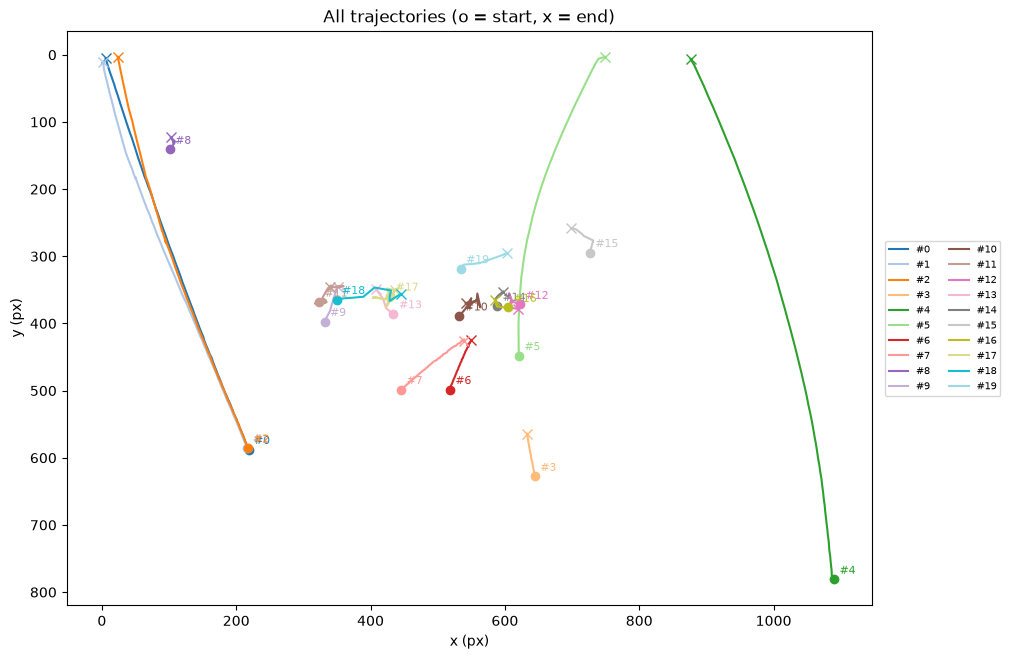

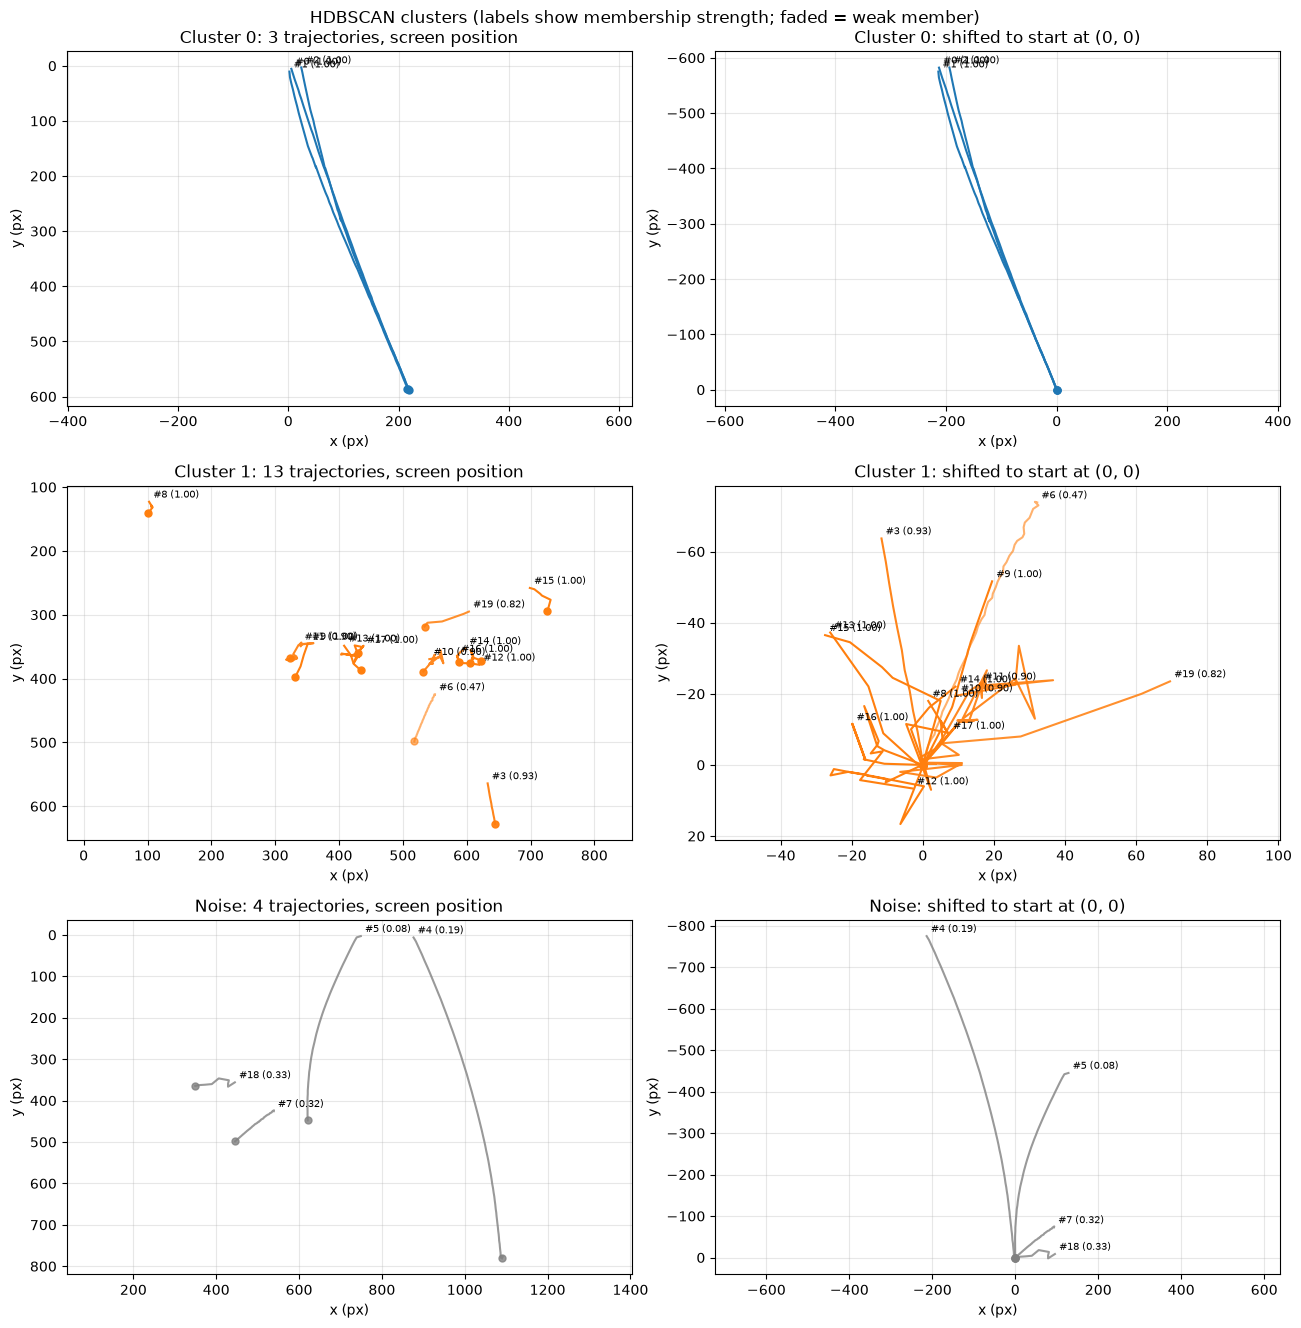

In [24]:
#==========================================
# 4. Graphing the Trajectories and Clusters
#==========================================

def plot_all_trajectories(raw_trajectory_input, save_path=None):
    """Figure 1: every trajectory in its real screen position, one color each, no clustering."""
    fig, ax = plt.subplots(figsize=(10, 7))
    cmap = plt.get_cmap("tab20")

    for idx, track in enumerate(raw_trajectory_input):
        t = np.asarray(track)
        color = cmap(idx % 20)
        ax.plot(t[:, 0], t[:, 1], "-", color=color, linewidth=1.5, label=f"#{idx}")
        ax.plot(t[0, 0], t[0, 1], "o", color=color, markersize=6)   # start
        ax.plot(t[-1, 0], t[-1, 1], "x", color=color, markersize=7)  # end
        ax.annotate(f"#{idx}", t[0], textcoords="offset points", xytext=(4, 4), fontsize=8, color=color)

    ax.invert_yaxis()  # pixel coordinates: y grows downward
    ax.set_aspect("equal")
    ax.set_title("All trajectories (o = start, x = end)")
    ax.set_xlabel("x (px)")
    ax.set_ylabel("y (px)")
    ax.legend(fontsize=7, ncol=2, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120)
    return fig


def plot_clusters(raw_trajectory_input, cluster_labels, probabilities, save_path=None):
    """Figure 2: one row per cluster (noise last).
    Left column  = trajectories in their real screen position.
    Right column = the same trajectories shifted to start at (0, 0), which is what the model compares.
    Line opacity follows membership strength, so weak members look faded."""
    cluster_labels = np.asarray(cluster_labels)
    clusters = sorted(c for c in set(cluster_labels) if c != -1)
    if -1 in cluster_labels:
        clusters.append(-1)

    fig, axes = plt.subplots(len(clusters), 2, figsize=(13, 4.5 * len(clusters)), squeeze=False)
    cmap = plt.get_cmap("tab10")

    for row, label in enumerate(clusters):
        color = "gray" if label == -1 else cmap(label % 10)
        name = "Noise" if label == -1 else f"Cluster {label}"
        members = np.where(cluster_labels == label)[0]
        ax_abs, ax_rel = axes[row]

        for idx in members:
            t = np.asarray(raw_trajectory_input[idx])
            rel = t - t[0]
            alpha = 0.25 + 0.75 * probabilities[idx] if label != -1 else 0.8
            lbl = f"#{idx} ({probabilities[idx]:.2f})"
            for ax, pts in ((ax_abs, t), (ax_rel, rel)):
                ax.plot(pts[:, 0], pts[:, 1], "-", color=color, alpha=alpha, linewidth=1.5)
                ax.plot(pts[0, 0], pts[0, 1], "o", color=color, alpha=alpha, markersize=5)
                ax.annotate(lbl, pts[-1], textcoords="offset points", xytext=(3, 3), fontsize=7)

        ax_abs.set_title(f"{name}: {len(members)} trajectories, screen position")
        ax_rel.set_title(f"{name}: shifted to start at (0, 0)")
        for ax in (ax_abs, ax_rel):
            ax.invert_yaxis()
            ax.set_aspect("equal", adjustable="datalim")
            ax.grid(alpha=0.3)
            ax.set_xlabel("x (px)")
            ax.set_ylabel("y (px)")

    fig.suptitle("HDBSCAN clusters (labels show membership strength; faded = weak member)")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120)
    return fig


plot_all_trajectories(raw_trajectory_input)
plot_clusters(raw_trajectory_input, cluster_labels, clusterer.probabilities_)
plt.show()

In [5]:
def plot_all_trajectories(raw_trajectory_input, save_path=None):
    """Figure 1: every trajectory in its real screen position, one color each, no clustering."""
    fig, ax = plt.subplots(figsize=(10, 7))
    cmap = plt.get_cmap("tab20")

    for idx, track in enumerate(raw_trajectory_input):
        t = np.asarray(track)
        color = cmap(idx % 20)
        ax.plot(t[:, 0], t[:, 1], "-", color=color, linewidth=1.5, label=f"#{idx}")
        ax.plot(t[0, 0], t[0, 1], "o", color=color, markersize=6)   # start
        ax.plot(t[-1, 0], t[-1, 1], "x", color=color, markersize=7)  # end
        ax.annotate(f"#{idx}", t[0], textcoords="offset points", xytext=(4, 4), fontsize=8, color=color)

    ax.invert_yaxis()  # pixel coordinates: y grows downward
    ax.set_aspect("equal")
    ax.set_title("All trajectories (o = start, x = end)")
    ax.set_xlabel("x (px)")
    ax.set_ylabel("y (px)")
    ax.legend(fontsize=7, ncol=2, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120)
    return fig

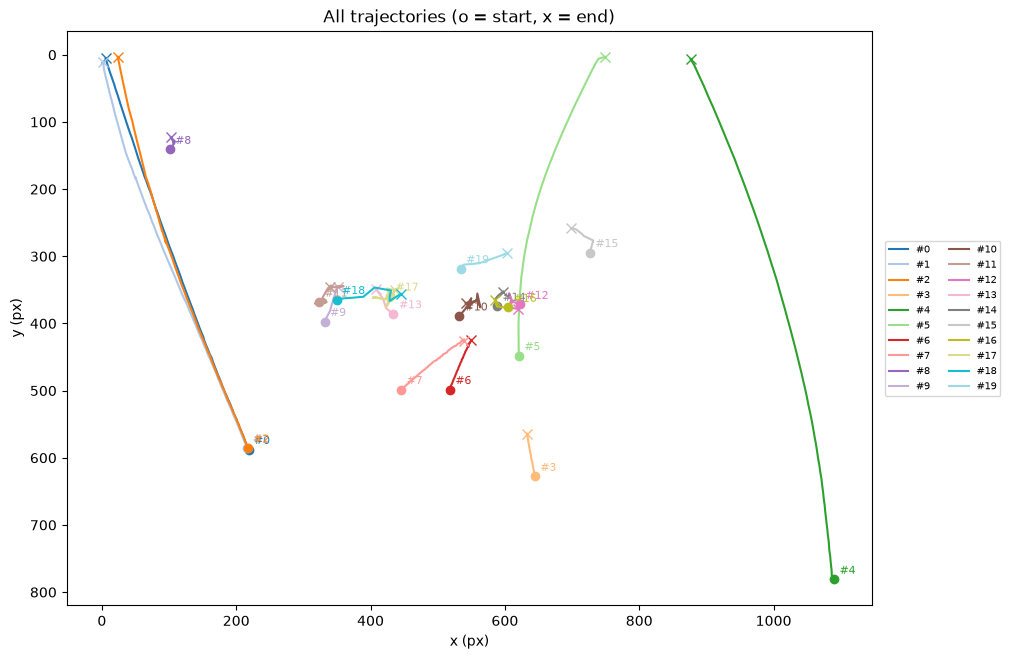

In [8]:
plot_all_trajectories(raw_trajectory_input)
plt.show()